# T0103 — Deep EDA & kiểm toán khuyết thiếu ETT v2.0

**Project:** ETT_GRID_VIS_2026 · **Owner:** E (Visual QA), phối hợp A · CPU-only.

**What:** Clean 14 cột, 7 biến vật lý, derived features và quality flags.
**Why:** Xác định chất lượng, phân phối, bằng chứng tính dừng và đa cộng tuyến trước WP02.
**How:** Missing matrix, histogram/small multiples, Pearson/Spearman heatmaps, ADF và VIF tables.

1. Contract & provenance → 2. Missing/gap audit → 3. Distribution/IQR →
4. ADF → 5. Correlation/VIF → 6. Operational handoff & assertions.

**Giới hạn:** Dataset lịch sử, không phải giám sát trực tiếp hoặc chứng nhận an toàn.
OT giữ °C; đơn vị tải chưa xác minh, không tự gán MW/MVar. Ngưỡng 85/95°C là quy ước dự án.
Timestamp Parquet là datetime64[ns], timezone unknown, **không phải chuỗi RFC3339 có offset**;
không tự thêm Z/UTC. Không sửa raw/docs/clean, không điền null hoặc xóa outlier.
Artifact duy nhất được notebook ghi: `output/figures/missing_matrix.png`.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata as package_metadata
import json
import os
import random
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import missingno as msno
import pyarrow.parquet as pq
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller
from statsmodels.stats.outliers_influence import variance_inflation_factor
from IPython.display import display, Markdown

SEED = 2026
random.seed(SEED)
np.random.seed(SEED)
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'AGENTS.md').is_file() and (p / 'data/processed').is_dir()), None)
assert ROOT is not None, 'Launch from repository root or notebooks/'
assert Path(sys.executable).resolve() == (ROOT / '.venv/Scripts/python.exe').resolve(), (
    'Use the approved project .venv kernel'
)
sys.path.insert(0, str(ROOT))
from src.data.constants import CLEAN_COLUMNS, CADENCE_MINUTES, MEASUREMENTS

INPUT = ROOT / 'data/processed/clean_ett.parquet'
FIGURE = ROOT / 'output/figures/missing_matrix.png'
LOADS = ['HUFL', 'HULL', 'MUFL', 'MULL', 'LUFL', 'LULL']
PHYSICAL = [*LOADS, 'OT']
NUMERIC = [*PHYSICAL, 'total_useful_load', 'total_unuseful_load', 'reactive_ratio']
ALPHA = 0.05
MIN_PAIRS = 30
ADF_MAX_LAG_HOURS = 24
ADF_MIN_SAMPLES = 50
MIN_VIF_SAMPLES = 30
NAVY, BLUE, ORANGE, SLATE = '#1E3A8A', '#0072B2', '#E69F00', '#64748B'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 180, 'axes.spines.top': False,
    'axes.spines.right': False, 'axes.spines.left': False,
    'axes.titleweight': 'bold', 'axes.grid': False, 'font.size': 10,
    'grid.color': '#E2E8F0', 'axes.edgecolor': '#64748B',
})
versions = {name: package_metadata.version(name) for name in
            ['pandas', 'numpy', 'scipy', 'statsmodels', 'missingno',
             'matplotlib', 'pyarrow', 'ipykernel']}
display(pd.Series({'python': sys.version.split()[0], 'interpreter': sys.executable,
                   **versions}, name='execution environment'))

python                                                    3.11.1
interpreter    f:\Study Materials\specialized_subject\Visuali...
pandas                                                     3.0.6
numpy                                                      2.4.6
scipy                                                     1.17.1
statsmodels                                               0.15.0
missingno                                                  0.5.2
matplotlib                                                3.11.2
pyarrow                                                   25.0.1
ipykernel                                                  7.4.0
Name: execution environment, dtype: str

## 1. Contract, shape/dtypes và provenance
Đọc snapshot Parquet một lần; kiểm tra cột, kiểu, dataset IDs và metadata trước thống kê.
Mọi kết quả dưới đây gắn với hash đầu vào. Snapshot hash raw/docs bảo đảm notebook không sửa nguồn.

In [2]:
protected_paths = [p for folder in ['data/raw', 'docs']
                   for p in (ROOT / folder).rglob('*') if p.is_file()]
protected_hashes = {str(p): hashlib.sha256(p.read_bytes()).hexdigest()
                    for p in protected_paths}
input_hash = hashlib.sha256(INPUT.read_bytes()).hexdigest()
df = pd.read_parquet(INPUT)
metadata = {k.decode(): v.decode() for k, v in pq.read_schema(INPUT).metadata.items()}
assert tuple(df.columns) == CLEAN_COLUMNS and df.shape[1] == 14
assert df['timestamp'].dtype == np.dtype('datetime64[ns]')
assert df['timestamp'].dt.tz is None
assert df['dataset'].notna().all() and df['dataset'].isin(CADENCE_MINUTES).all()
assert metadata['schema_version'] == '2.0' and metadata['timezone'] == 'unknown'
assert df['is_imputed'].dtype == np.dtype(bool)
for column in NUMERIC:
    assert df[column].dtype == np.dtype('float32'), column
for column in ['dataset', 'thermal_regime']:
    assert pd.api.types.is_string_dtype(df[column]), column
datasets = list(df['dataset'].unique())
display(Markdown(f'**Shape:** {df.shape[0]:,} × {df.shape[1]} · '
                 f'**Dataset:** {datasets} · **SHA-256:** `{input_hash}`'))
display(df.dtypes.rename('dtype').to_frame())
display(pd.Series(metadata, name='Parquet metadata').to_frame())
display(df.head())

**Shape:** 17,420 × 14 · **Dataset:** ['ETTh1'] · **SHA-256:** `a1eb3f65fa765281607904a5ae0c79af9d17c90d823d107db329e14bb4610105`

,dtype
dataset,str
timestamp,datetime64[ns]
OT,float32
HUFL,float32
HULL,float32
MUFL,float32
MULL,float32
LUFL,float32
LULL,float32
total_useful_load,float32


,Parquet metadata
schema_version,2.0
dataset,ETTh1
seed,2026
source_hash,f18de3ad269cef59bb07b5438d79bb3042d3be49bdeecf...
source_hash_algorithm,sha256_lf_normalized
generated_at,2026-10-28T02:27:12.398690+00:00
timezone,unknown
parameters,"{""cadence_minutes"": 60, ""critical_threshold_c""..."
quality_audit,"{""duplicate_count"": 0, ""gap_count"": 0, ""impute..."


,dataset,timestamp,OT,HUFL,HULL,MUFL,MULL,LUFL,LULL,total_useful_load,total_unuseful_load,reactive_ratio,thermal_regime,is_imputed
0,ETTh1,2016-07-01 00:00:00,30.531000,5.827,2.009,1.599,0.462,4.203,1.340,11.629000,3.811,0.327715,Normal,False
1,ETTh1,2016-07-01 01:00:00,27.787001,5.693,2.076,1.492,0.426,4.142,1.371,11.327000,3.873,0.341926,Normal,False
2,ETTh1,2016-07-01 02:00:00,27.787001,5.157,1.741,1.279,0.355,3.777,1.218,10.212999,3.314,0.324488,Normal,False
3,ETTh1,2016-07-01 03:00:00,25.044001,5.090,1.942,1.279,0.391,3.807,1.279,10.176001,3.612,0.354953,Normal,False
4,ETTh1,2016-07-01 04:00:00,21.948000,5.358,1.942,1.492,0.462,3.868,1.279,10.718000,3.683,0.343628,Normal,False


## 2. Missing data & temporal integrity (FReq003, AC-03)
Ma trận hiển thị **tất cả 14 cột** theo từng dataset; mỗi hàng tương ứng một mẫu quan sát,
không phải lưới thời gian đã lấp khoảng trống. Vì vậy gap audit riêng là bắt buộc.
Null `reactive_ratio` khi useful total≤0 là **null có chủ đích**, không phải cảm biến bị thiếu.
Infinity được kiểm kê riêng, không bị coi là giá trị hợp lệ; không thay null bằng 0.

In [3]:
missing_records, integrity_records, gap_records = [], [], []
for dataset, group in df.groupby('dataset', sort=False):
    for column in CLEAN_COLUMNS:
        count = int(group[column].isna().sum())
        nonfinite = (int(np.isinf(group[column].to_numpy()).sum())
                     if column in NUMERIC else 0)
        missing_records.append({'dataset': dataset, 'variable': column,
                                'missing_count': count,
                                'missing_percent': 100 * count / len(group),
                                'infinite_count': nonfinite})
    time = group['timestamp'].sort_values()
    expected = pd.Timedelta(minutes=CADENCE_MINUTES[dataset])
    deltas = time.diff()
    gaps = deltas[deltas > expected]
    offgrid = deltas.dropna().loc[(deltas.dropna() <= pd.Timedelta(0)) |
                                (deltas.dropna() % expected != pd.Timedelta(0))]
    for index, delta in gaps.items():
        end = time.loc[index]
        gap_records.append({'dataset': dataset, 'before': end - delta,
                            'after': end, 'elapsed_hours': delta.total_seconds() / 3600,
                            'absent_samples': (int(delta / expected) - 1
                                               if delta % expected == pd.Timedelta(0)
                                               else None)})
    ratio = group['reactive_ratio']
    should_null = ((group['total_useful_load'] <= 0) |
                   group['total_useful_load'].isna() |
                   group['total_unuseful_load'].isna())
    integrity_records.append({
        'dataset': dataset, 'rows': len(group), 'first': time.min(), 'last': time.max(),
        'expected_interval_minutes': CADENCE_MINUTES[dataset],
        'timestamps_missing': int(group['timestamp'].isna().sum()),
        'duplicate_keys': int(group.duplicated(['dataset', 'timestamp']).sum()),
        'original_order_increasing': group['timestamp'].is_monotonic_increasing,
        'gap_intervals': len(gaps), 'off_grid_or_zero_steps': len(offgrid),
        'imputed_rows': int(group['is_imputed'].sum()),
        'intentional_ratio_nulls': int((ratio.isna() & should_null).sum()),
        'unexpected_ratio_nulls': int((ratio.isna() & ~should_null).sum()),
        'ratio_present_despite_invalid_denominator': int((ratio.notna() & should_null).sum()),
    })
missing_table = pd.DataFrame(missing_records)
integrity_table = pd.DataFrame(integrity_records)
gap_table = pd.DataFrame(gap_records, columns=[
    'dataset', 'before', 'after', 'elapsed_hours', 'absent_samples'])
display(missing_table)
display(integrity_table)
display(gap_table if len(gap_table) else Markdown('**Không phát hiện gap thời gian trong snapshot.**'))

,dataset,variable,missing_count,missing_percent,infinite_count
0,ETTh1,dataset,0,0.000000,0
1,ETTh1,timestamp,0,0.000000,0
2,ETTh1,OT,0,0.000000,0
3,ETTh1,HUFL,0,0.000000,0
4,ETTh1,HULL,0,0.000000,0
5,ETTh1,MUFL,0,0.000000,0
6,ETTh1,MULL,0,0.000000,0
7,ETTh1,LUFL,0,0.000000,0
8,ETTh1,LULL,0,0.000000,0
9,ETTh1,total_useful_load,0,0.000000,0


,dataset,rows,first,last,expected_interval_minutes,timestamps_missing,duplicate_keys,original_order_increasing,gap_intervals,off_grid_or_zero_steps,imputed_rows,intentional_ratio_nulls,unexpected_ratio_nulls,ratio_present_despite_invalid_denominator
0,ETTh1,17420,2016-07-01,2018-06-26 19:00:00,60,0,0,True,0,0,0,2376,0,0


**Không phát hiện gap thời gian trong snapshot.**

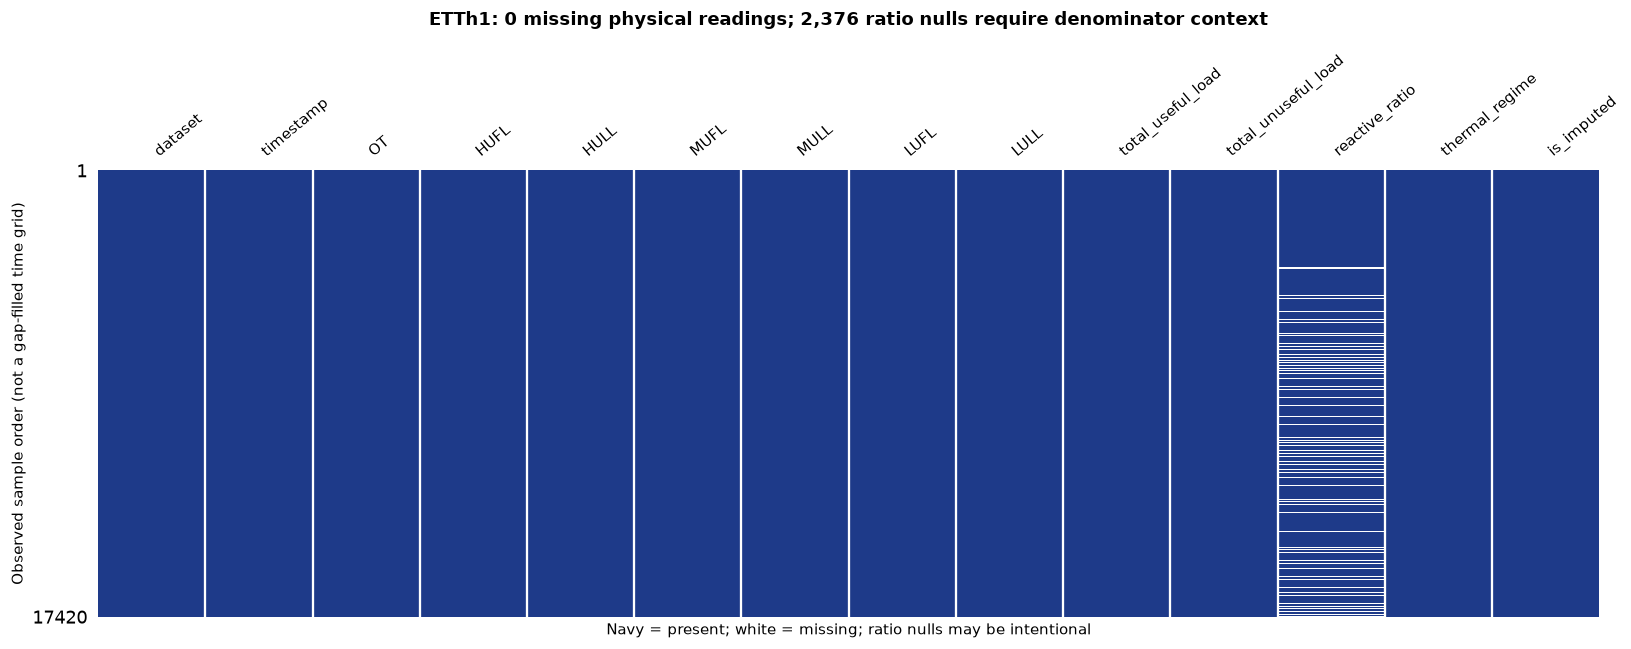

Exported: f:\Study Materials\specialized_subject\Visualization\Visualization_gr\data_visualization_project\figures\missing_matrix.png


In [4]:
fig, axes = plt.subplots(len(datasets), 1, figsize=(15, 6 * len(datasets)), squeeze=False)
for axis, dataset in zip(axes[:, 0], datasets):
    group = df.loc[df['dataset'] == dataset].sort_values('timestamp')
    measured_missing = int(group[PHYSICAL].isna().sum().sum())
    ratio_nulls = int(group['reactive_ratio'].isna().sum())
    msno.matrix(group.loc[:, CLEAN_COLUMNS], ax=axis, sparkline=False,
                color=(0.12, 0.23, 0.54), fontsize=10, labels=True,
                label_rotation=40, figsize=(15, 6))
    axis.set_title(f'{dataset}: {measured_missing:,} missing physical readings; '
                   f'{ratio_nulls:,} ratio nulls require denominator context', pad=18)
    axis.set_ylabel('Observed sample order (not a gap-filled time grid)')
    axis.set_xlabel('Navy = present; white = missing; ratio nulls may be intentional')
    for spine in axis.spines.values():
        spine.set_visible(False)
fig.tight_layout()
FIGURE.parent.mkdir(parents=True, exist_ok=True)
temporary_figure = FIGURE.with_name(FIGURE.name + '.tmp')
assert not temporary_figure.exists(), 'Existing figure tmp belongs to another run'
try:
    fig.savefig(temporary_figure, format='png', dpi=180, bbox_inches='tight',
                facecolor='white')
    os.replace(temporary_figure, FIGURE)
finally:
    if temporary_figure.exists():
        temporary_figure.unlink()
plt.show()
print('Exported:', FIGURE)

## 3. Distribution, skewness và IQR outliers
Mean/Std dùng mẫu (ddof=1); median/IQR từ empirical quantiles; kurtosis là **excess kurtosis**
(normal=0, Pandas unbiased estimator). IQR bounds = Q1−1.5×IQR, Q3+1.5×IQR.
Điểm ngoài bounds là **ứng viên ngoại lai**, không tự xem là lỗi cảm biến và không xóa.
|skew|≥1 chỉ là heuristic mô tả, không phải kiểm định phân phối; missing/constant phải được gắn ngữ cảnh.

,dataset,variable,n_finite,mean,std_sample,median,min,max,q25,q75,iqr,skewness,excess_kurtosis,iqr_lower,iqr_upper,outlier_candidates,outlier_percent,quality
0,ETTh1,HUFL,17420,7.3751,7.0677,8.774,-22.706,23.644,5.827,11.788,5.961,-1.3780,1.9524,-3.1145,20.7295,1824,10.4707,ok
1,ETTh1,HULL,17420,2.2422,2.0423,2.210,-4.756,10.114,0.737,3.684,2.947,0.1010,-0.3057,-3.6835,8.1045,51,0.2928,ok
2,ETTh1,MUFL,17420,4.3002,6.8270,5.970,-25.088,17.341,3.296,8.635,5.339,-1.6054,2.3544,-4.7125,16.6435,2005,11.5098,ok
3,ETTh1,MULL,17420,0.8816,1.8093,0.959,-5.934,7.747,-0.284,2.203,2.487,-0.1382,-0.2405,-4.0145,5.9335,78,0.4478,ok
4,ETTh1,LUFL,17420,3.0661,1.1645,2.833,-1.188,8.498,2.315,3.625,1.310,1.2666,2.9616,0.3500,5.5900,561,3.2204,ok
5,ETTh1,LULL,17420,0.8569,0.5996,0.975,-1.371,3.046,0.670,1.218,0.548,-1.3624,2.0784,-0.1520,2.0400,1714,9.8393,ok
6,ETTh1,OT,17420,13.3247,8.5669,11.396,-4.080,46.007,6.964,18.079,11.115,0.9683,0.7783,-9.7085,34.7515,471,2.7038,ok


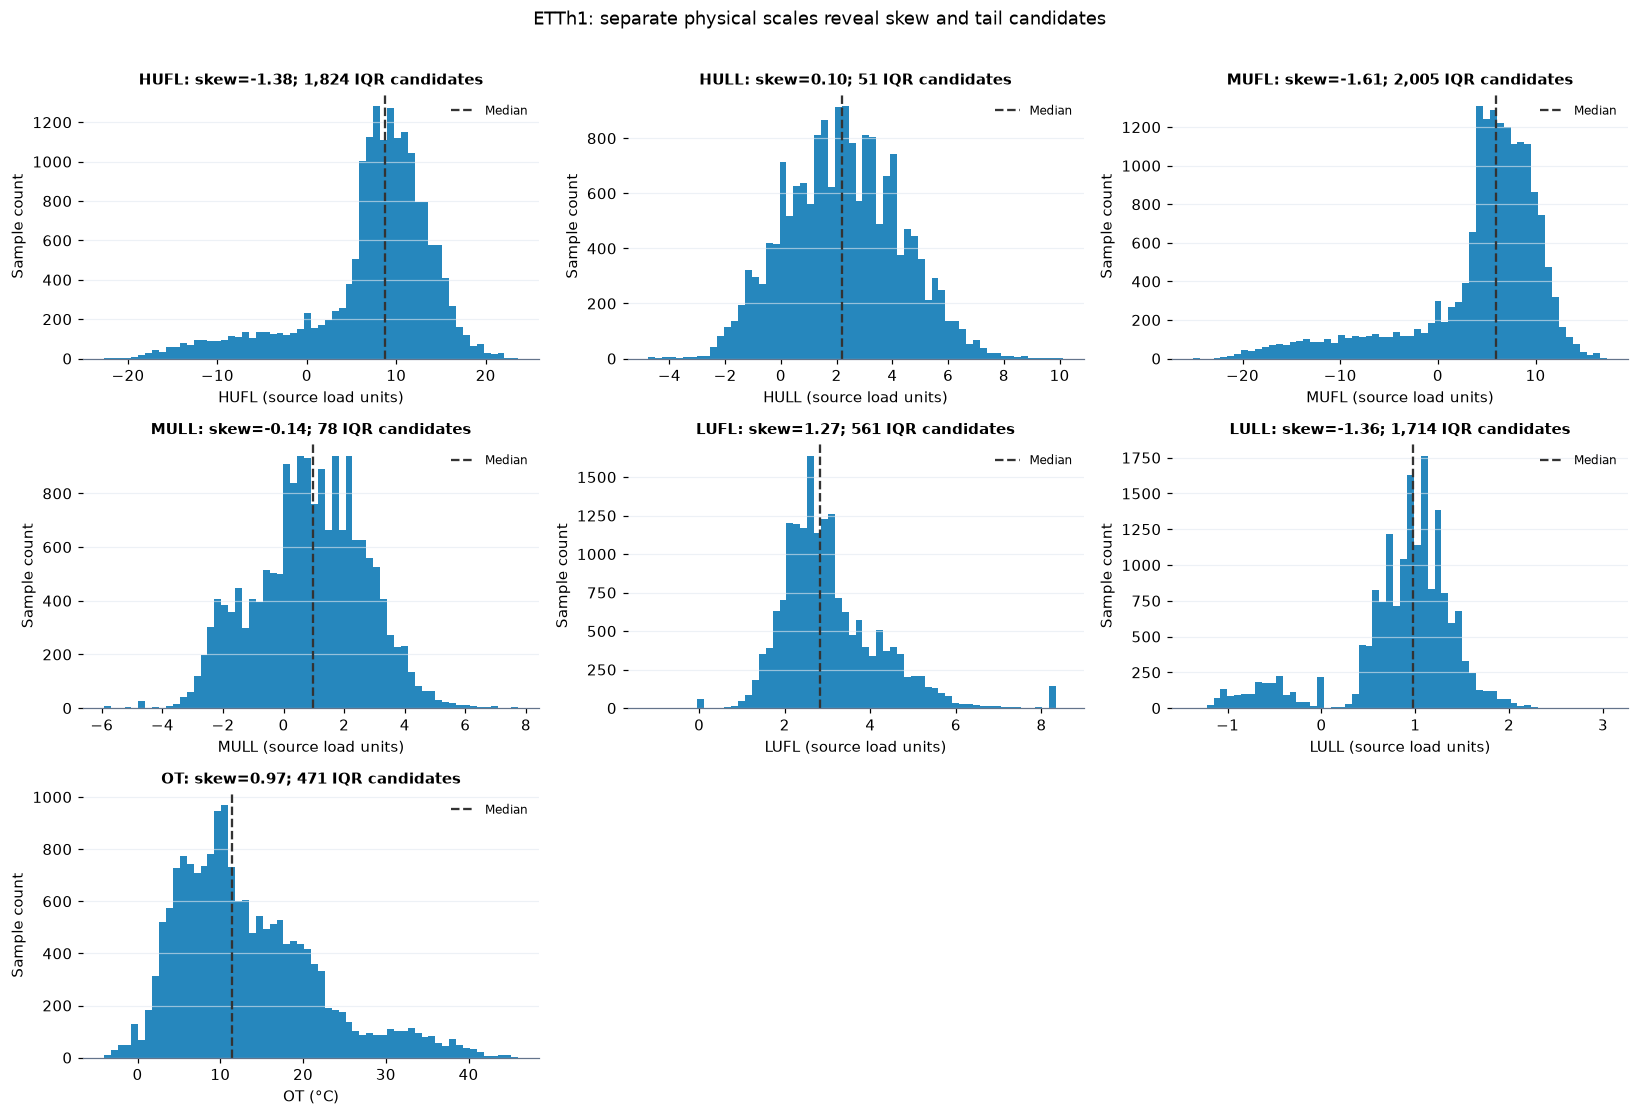

In [5]:
distribution_records = []
for dataset, group in df.groupby('dataset', sort=False):
    for column in PHYSICAL:
        values = group[column].replace([np.inf, -np.inf], np.nan).dropna().astype('float64')
        q1, q3 = values.quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        candidates = int(((values < low) | (values > high)).sum())
        skew = values.skew() if len(values) >= 3 and values.nunique() > 1 else np.nan
        distribution_records.append({
            'dataset': dataset, 'variable': column, 'n_finite': len(values),
            'mean': values.mean(), 'std_sample': values.std(ddof=1),
            'median': values.median(), 'min': values.min(), 'max': values.max(),
            'q25': q1, 'q75': q3, 'iqr': iqr, 'skewness': skew,
            'excess_kurtosis': (values.kurt() if len(values) >= 4 and values.nunique() > 1
                                 else np.nan),
            'iqr_lower': low, 'iqr_upper': high, 'outlier_candidates': candidates,
            'outlier_percent': 100 * candidates / len(values) if len(values) else np.nan,
            'quality': 'constant' if values.nunique() == 1 else ('empty' if len(values) == 0 else 'ok'),
        })
distribution_table = pd.DataFrame(distribution_records)
display(distribution_table.round(4))
for dataset, group in df.groupby('dataset', sort=False):
    fig, axes = plt.subplots(3, 3, figsize=(15, 10))
    for axis, column in zip(axes.flat, PHYSICAL):
        values = group[column].replace([np.inf, -np.inf], np.nan).dropna()
        row = distribution_table.query('dataset == @dataset and variable == @column').iloc[0]
        axis.hist(values, bins=60, color=BLUE, edgecolor='none', alpha=0.85)
        axis.axvline(row['median'], color='#333333', linestyle='--', label='Median')
        axis.set_title(f'{column}: skew={row.skewness:.2f}; '
                       f'{int(row.outlier_candidates):,} IQR candidates', fontsize=10)
        axis.set_xlabel('OT (°C)' if column == 'OT' else f'{column} (source load units)')
        axis.set_ylabel('Sample count')
        axis.grid(axis='y', alpha=0.6)
        axis.legend(frameon=False, fontsize=8)
    for axis in axes.flat[len(PHYSICAL):]:
        axis.set_visible(False)
    fig.suptitle(f'{dataset}: separate physical scales reveal skew and tail candidates', y=1.01)
    fig.tight_layout()
    plt.show()

## 4. Augmented Dickey–Fuller (ADF)
H0: unit root; H1: stationary quanh intercept với `regression='c'`. Chọn lag bằng AIC trong
cửa sổ tối đa 24 giờ (ETTh: 24, ETTm1: 96 mẫu), giới hạn bởi cỡ mẫu hợp lệ.
**p<0.05 chỉ bác bỏ H0 trong đặc tả này**, không chứng minh mùa vụ, mọi dạng tính dừng,
hoặc kết luận nhân quả. ADF có giới hạn khi seasonal roots/structural breaks; T0201 cần STL và residual diagnostics.

Không dropna rồi nối thời gian mù: chọn **đoạn liên tục hữu hạn dài nhất** cho từng biến/dataset,
ghi rõ độ bao phủ và điểm đầu/cuối. Constant/thiếu mẫu → null kèm lý do, không fake p=0.

In [6]:
def longest_finite_segment(group, variable, cadence):
    ordered = group.sort_values('timestamp').reset_index(drop=True)
    valid = np.isfinite(ordered[variable].to_numpy(dtype='float64'))
    contiguous = ordered['timestamp'].diff().eq(cadence).to_numpy()
    starts = valid & ~(np.r_[False, valid[:-1]] & contiguous)
    labels = np.cumsum(starts)
    segments = [(label, int(((labels == label) & valid).sum()))
                for label in np.unique(labels[valid])]
    if not segments:
        return ordered.iloc[:0]
    best = max(segments, key=lambda item: item[1])[0]
    return ordered.loc[(labels == best) & valid]

def adf_record(group, dataset, variable):
    cadence = pd.Timedelta(minutes=CADENCE_MINUTES[dataset])
    segment = longest_finite_segment(group, variable, cadence)
    values = segment[variable].to_numpy(dtype='float64')
    row = {'dataset': dataset, 'variable': variable, 'total_rows': len(group),
           'segment_rows': len(segment), 'coverage_percent': 100 * len(segment) / len(group),
           'start': segment['timestamp'].min(), 'end': segment['timestamp'].max(),
           'adf_statistic': np.nan, 'p_value': np.nan, 'critical_1pct': np.nan,
           'critical_5pct': np.nan, 'selected_lag': None, 'regression': 'c',
           'nobs': None, 'maxlag': None, 'status': 'ok', 'conclusion': ''}
    if len(values) < ADF_MIN_SAMPLES:
        row.update(status='insufficient_contiguous_samples', conclusion='Not evaluated')
    elif np.ptp(values) == 0:
        row.update(status='constant', conclusion='Not evaluated: ADF undefined')
    else:
        maxlag = min(int(ADF_MAX_LAG_HOURS * 60 / CADENCE_MINUTES[dataset]),
                     len(values) // 2 - 2)
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            statistic, pvalue, lag, nobs, critical, *_ = adfuller(
                values, maxlag=maxlag, regression='c', autolag='AIC')
        row.update(adf_statistic=statistic, p_value=pvalue, critical_1pct=critical['1%'],
                   critical_5pct=critical['5%'], selected_lag=lag, nobs=nobs, maxlag=maxlag,
                   warnings='; '.join(str(w.message) for w in caught),
                   conclusion=('Reject unit root H0 (5%)' if pvalue < ALPHA else
                               'Do not reject unit root H0 (5%)'))
    return row

adf_table = pd.DataFrame([adf_record(group, dataset, variable)
                          for dataset, group in df.groupby('dataset', sort=False)
                          for variable in PHYSICAL])
display(adf_table)

,dataset,variable,total_rows,segment_rows,coverage_percent,start,end,adf_statistic,p_value,critical_1pct,critical_5pct,selected_lag,regression,nobs,maxlag,status,conclusion,warnings
0,ETTh1,HUFL,17420,17420,100.0,2016-07-01,2018-06-26 19:00:00,-10.310662,3.191822e-18,-3.430726,-2.861706,24,c,17395,24,ok,Reject unit root H0 (5%),adfuller currently returns a plain tuple whose...
1,ETTh1,HULL,17420,17420,100.0,2016-07-01,2018-06-26 19:00:00,-4.979366,2.437735e-05,-3.430726,-2.861706,24,c,17395,24,ok,Reject unit root H0 (5%),adfuller currently returns a plain tuple whose...
2,ETTh1,MUFL,17420,17420,100.0,2016-07-01,2018-06-26 19:00:00,-10.397676,1.945964e-18,-3.430726,-2.861706,24,c,17395,24,ok,Reject unit root H0 (5%),adfuller currently returns a plain tuple whose...
3,ETTh1,MULL,17420,17420,100.0,2016-07-01,2018-06-26 19:00:00,-4.639686,1.090767e-04,-3.430726,-2.861706,24,c,17395,24,ok,Reject unit root H0 (5%),adfuller currently returns a plain tuple whose...
4,ETTh1,LUFL,17420,17420,100.0,2016-07-01,2018-06-26 19:00:00,-9.932536,2.798199e-17,-3.430726,-2.861706,24,c,17395,24,ok,Reject unit root H0 (5%),adfuller currently returns a plain tuple whose...
5,ETTh1,LULL,17420,17420,100.0,2016-07-01,2018-06-26 19:00:00,-5.596512,1.293364e-06,-3.430726,-2.861706,24,c,17395,24,ok,Reject unit root H0 (5%),adfuller currently returns a plain tuple whose...
6,ETTh1,OT,17420,17420,100.0,2016-07-01,2018-06-26 19:00:00,-4.166546,7.502874e-04,-3.430726,-2.861706,24,c,17395,24,ok,Reject unit root H0 (5%),adfuller currently returns a plain tuple whose...


## 5. Pearson/Spearman correlation & multicollinearity (VIF)
Correlation dùng **pairwise finite observations** (min 30 cặp), ghi ma trận số cặp; constant hoặc
thiếu cặp → null. Spearman đo liên hệ thứ hạng đơn điệu, không thay thế lag analysis.
Heatmap dùng diverging blue–orange, cùng scale −1..1; không dùng cặp red–green.

VIF dùng **6 tải làm predictors**, không thêm OT/tổng tải/ratio để tránh đa cộng tuyến cơ học.
Complete-case rows, có intercept và chuẩn hóa tạm trong bộ nhớ để ổn định số học;
không thay đổi đơn vị trong nguồn hoặc artifact. VIF>5/>10 là heuristic, không phải quyết định loại biến.
Rank deficiency/perfect collinearity → Infinity có chú thích; constant/thiếu mẫu → null có lý do.

### ETTh1 — pair counts

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
HUFL,17420,17420,17420,17420,17420,17420,17420
HULL,17420,17420,17420,17420,17420,17420,17420
MUFL,17420,17420,17420,17420,17420,17420,17420
MULL,17420,17420,17420,17420,17420,17420,17420
LUFL,17420,17420,17420,17420,17420,17420,17420
LULL,17420,17420,17420,17420,17420,17420,17420
OT,17420,17420,17420,17420,17420,17420,17420


**ETTh1 — pearson coefficients**

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
HUFL,1.0000,0.1147,0.9874,0.0660,0.2914,0.0236,0.0599
HULL,0.1147,1.0000,0.0688,0.9305,0.2595,0.3776,0.2244
MUFL,0.9874,0.0688,1.0000,0.0463,0.1775,-0.0465,0.0509
MULL,0.0660,0.9305,0.0463,1.0000,0.1286,0.0694,0.2200
LUFL,0.2914,0.2595,0.1775,0.1286,1.0000,0.3346,0.1188
LULL,0.0236,0.3776,-0.0465,0.0694,0.3346,1.0000,0.0675
OT,0.0599,0.2244,0.0509,0.2200,0.1188,0.0675,1.0000


**ETTh1 — spearman coefficients**

,HUFL,HULL,MUFL,MULL,LUFL,LULL,OT
HUFL,1.0000,0.2988,0.9753,0.2227,0.3833,0.0901,-0.0613
HULL,0.2988,1.0000,0.2845,0.9247,0.2400,0.4389,0.1581
MUFL,0.9753,0.2845,1.0000,0.2353,0.2249,-0.0102,-0.0506
MULL,0.2227,0.9247,0.2353,1.0000,0.1042,0.1791,0.1946
LUFL,0.3833,0.2400,0.2249,0.1042,1.0000,0.4894,-0.0232
LULL,0.0901,0.4389,-0.0102,0.1791,0.4894,1.0000,0.1369
OT,-0.0613,0.1581,-0.0506,0.1946,-0.0232,0.1369,1.0000


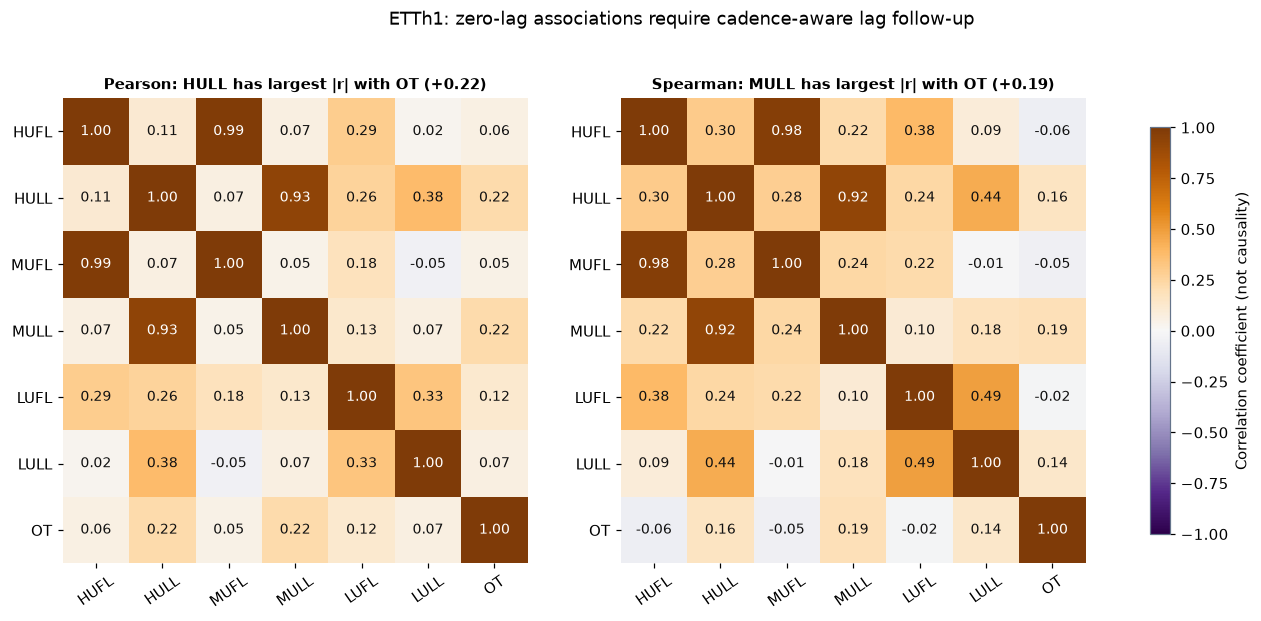

,dataset,variable,n_complete,rows_excluded,vif,design_rank,design_columns,status,warnings
0,ETTh1,HUFL,17420,0,100.420194,7,7,high_gt10,
1,ETTh1,HULL,17420,0,31.232431,7,7,high_gt10,
2,ETTh1,MUFL,17420,0,94.828331,7,7,high_gt10,
3,ETTh1,MULL,17420,0,26.413395,7,7,high_gt10,
4,ETTh1,LUFL,17420,0,2.324788,7,7,below_5,
5,ETTh1,LULL,17420,0,3.962995,7,7,below_5,


In [7]:
correlations, pair_counts = {}, {}
for dataset, group in df.groupby('dataset', sort=False):
    finite = group[PHYSICAL].astype('float64').replace([np.inf, -np.inf], np.nan)
    presence = finite.notna().astype('int64')
    counts = presence.T @ presence
    pair_counts[dataset] = counts
    display(Markdown(f'### {dataset} — pair counts'))
    display(counts)
    fig, axes = plt.subplots(1, 2, figsize=(15, 6))
    for axis, method in zip(axes, ['pearson', 'spearman']):
        matrix = finite.corr(method=method, min_periods=MIN_PAIRS)
        correlations[(dataset, method)] = matrix
        image = axis.imshow(np.ma.masked_invalid(matrix.to_numpy()),
                            vmin=-1, vmax=1, cmap='PuOr_r')
        axis.set_xticks(range(7), PHYSICAL, rotation=35)
        axis.set_yticks(range(7), PHYSICAL)
        ot_load = matrix.loc[LOADS, 'OT'].dropna()
        strongest = ot_load.abs().idxmax() if len(ot_load) else None
        title = (f'{method.title()}: {strongest} has largest |r| with OT '
                 f'({ot_load[strongest]:+.2f})' if strongest else
                 f'{method.title()}: no finite load–OT coefficients')
        axis.set_title(title, fontsize=10)
        for i in range(7):
            for j in range(7):
                value = matrix.iloc[i, j]
                label = f'{value:.2f}' if np.isfinite(value) else 'N/A'
                axis.text(j, i, label, ha='center', va='center', fontsize=9,
                          color='white' if np.isfinite(value) and abs(value) > 0.6 else '#111111')
        for spine in axis.spines.values():
            spine.set_visible(False)
        display(Markdown(f'**{dataset} — {method} coefficients**'))
        display(matrix.round(4))
    fig.colorbar(image, ax=axes, shrink=0.8, label='Correlation coefficient (not causality)')
    fig.suptitle(f'{dataset}: zero-lag associations require cadence-aware lag follow-up')
    plt.show()

def vif_records(group, dataset):
    complete = group[LOADS].astype('float64').replace([np.inf, -np.inf], np.nan).dropna()
    rows = []
    if len(complete) < MIN_VIF_SAMPLES:
        return [{'dataset': dataset, 'variable': c, 'n_complete': len(complete),
                 'vif': np.nan, 'status': 'insufficient_complete_cases'} for c in LOADS]
    scales = complete.std(ddof=0)
    active = scales.index[scales > 0].tolist()
    for column in scales.index[scales == 0]:
        rows.append({'dataset': dataset, 'variable': column, 'n_complete': len(complete),
                     'vif': np.nan, 'status': 'constant_predictor'})
    if not active:
        return rows
    standard = (complete[active] - complete[active].mean()) / scales[active]
    design = sm.add_constant(standard, has_constant='add').to_numpy()
    rank = int(np.linalg.matrix_rank(design))
    for position, column in enumerate(active, start=1):
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter('always')
            value = float(variance_inflation_factor(design, position))
        # A predictor adds no independent rank: numerical near-1 R² must not
        # hide exact collinearity behind an implementation-specific finite cap.
        if np.linalg.matrix_rank(np.delete(design, position, axis=1)) == rank:
            value = np.inf
        status = ('perfect_collinearity' if np.isinf(value) else
                  'high_gt10' if value > 10 else 'elevated_gt5' if value > 5 else 'below_5')
        rows.append({'dataset': dataset, 'variable': column, 'n_complete': len(complete),
                     'rows_excluded': len(group) - len(complete), 'vif': value,
                     'design_rank': rank, 'design_columns': design.shape[1],
                     'status': status, 'warnings': '; '.join(str(w.message) for w in caught)})
    return rows

vif_table = pd.DataFrame([row for dataset, group in df.groupby('dataset', sort=False)
                         for row in vif_records(group, dataset)])
display(vif_table)

## 6. Operational insights & bàn giao WP02
Tóm tắt dưới đây được tính từ chính snapshot đang lọc, không dùng insight viết sẵn.
ADF không nhận diện chu kỳ tuần/ngày; nonstationarity và seasonality là các khái niệm khác nhau.
T0201 kiểm tra STL theo period 24/96, reconstruction và coverage; T0202 căn timestamp cho lag 0–12h,
so sánh Pearson/Spearman theo dataset, không suy luận tác nhân gây quá nhiệt chỉ từ correlation.

In [8]:
summary_lines = ['### Kết quả định lượng theo snapshot']
for dataset in datasets:
    audit = integrity_table.loc[integrity_table.dataset == dataset].iloc[0]
    dist = distribution_table.loc[distribution_table.dataset == dataset]
    adf = adf_table.loc[adf_table.dataset == dataset]
    vif = vif_table.loc[vif_table.dataset == dataset]
    pearson = correlations[(dataset, 'pearson')].loc[LOADS, 'OT'].dropna()
    spearman = correlations[(dataset, 'spearman')].loc[LOADS, 'OT'].dropna()
    missing_n = int(missing_table.loc[(missing_table.dataset == dataset) &
                                     missing_table.variable.isin(PHYSICAL), 'missing_count'].sum())
    rejected = adf.loc[(adf.status == 'ok') & (adf.p_value < ALPHA), 'variable'].tolist()
    not_rejected = adf.loc[(adf.status == 'ok') & (adf.p_value >= ALPHA), 'variable'].tolist()
    high_vif = vif.loc[vif.vif > 10, 'variable'].tolist()
    skewed = dist.loc[dist.skewness.abs() >= 1, 'variable'].tolist()
    summary_lines += [f'**{dataset}** — {int(audit.rows):,} quan sát:',
        f'- Physical missing: **{missing_n}**; gap intervals: **{int(audit.gap_intervals)}**; '
        f'duplicate keys: **{int(audit.duplicate_keys)}**.',
        f'- Ratio null có chủ đích: **{int(audit.intentional_ratio_nulls):,}**; '
        f'null ngoài policy: **{int(audit.unexpected_ratio_nulls)}**.',
        '- Pearson load–OT: ' + ', '.join(f'{c}={pearson[c]:+.3f}' for c in pearson.index) + '.',
        '- Spearman load–OT: ' + ', '.join(f'{c}={spearman[c]:+.3f}' for c in spearman.index) + '.',
        f'- |skew|≥1: **{", ".join(skewed) or "không có"}**; IQR candidates chỉ gợi ý rà soát, không xóa.',
        f'- ADF (c, AIC, α=0.05): bác bỏ unit-root H0 ở **{", ".join(rejected) or "không có"}**; '
        f'chưa bác bỏ ở **{", ".join(not_rejected) or "không có"}**.',
        f'- VIF>10: **{", ".join(high_vif) or "không có"}**; '
        'không tự loại predictor hoặc suy nguyên nhân từ chỉ số này.',
        '- T0201: đối chiếu xu hướng/seasonal/residual; T0202: kiểm tra dấu lag và gap trước khi shift.',
    ]
summary_lines += ['**Giới hạn chung:** association ≠ causation; ADF rejection ≠ proof of all forms '
                 'of stationarity. Không có ngưỡng nhiệt phổ quát/khí hậu địa phương được suy từ notebook.']
summary_text = '\n\n'.join(summary_lines)
display(Markdown(summary_text))

### Kết quả định lượng theo snapshot

**ETTh1** — 17,420 quan sát:

- Physical missing: **0**; gap intervals: **0**; duplicate keys: **0**.

- Ratio null có chủ đích: **2,376**; null ngoài policy: **0**.

- Pearson load–OT: HUFL=+0.060, HULL=+0.224, MUFL=+0.051, MULL=+0.220, LUFL=+0.119, LULL=+0.067.

- Spearman load–OT: HUFL=-0.061, HULL=+0.158, MUFL=-0.051, MULL=+0.195, LUFL=-0.023, LULL=+0.137.

- |skew|≥1: **HUFL, MUFL, LUFL, LULL**; IQR candidates chỉ gợi ý rà soát, không xóa.

- ADF (c, AIC, α=0.05): bác bỏ unit-root H0 ở **HUFL, HULL, MUFL, MULL, LUFL, LULL, OT**; chưa bác bỏ ở **không có**.

- VIF>10: **HUFL, HULL, MUFL, MULL**; không tự loại predictor hoặc suy nguyên nhân từ chỉ số này.

- T0201: đối chiếu xu hướng/seasonal/residual; T0202: kiểm tra dấu lag và gap trước khi shift.

**Giới hạn chung:** association ≠ causation; ADF rejection ≠ proof of all forms of stationarity. Không có ngưỡng nhiệt phổ quát/khí hậu địa phương được suy từ notebook.

### Kết quả định lượng theo snapshot

**ETTh1** — 17,420 quan sát:

- Physical missing: **0**; gap intervals: **0**; duplicate keys: **0**.

- Ratio null có chủ đích: **2,376**; null ngoài policy: **0**.

- Pearson load–OT: HUFL=+0.060, HULL=+0.224, MUFL=+0.051, MULL=+0.220, LUFL=+0.119, LULL=+0.067.

- Spearman load–OT: HUFL=-0.061, HULL=+0.158, MUFL=-0.051, MULL=+0.195, LUFL=-0.023, LULL=+0.137.

- |skew|≥1: **HUFL, MUFL, LUFL, LULL**; IQR candidates chỉ gợi ý rà soát, không xóa.

- ADF (c, AIC, α=0.05): bác bỏ unit-root H0 ở **HUFL, HULL, MUFL, MULL, LUFL, LULL, OT**; chưa bác bỏ ở **không có**.

- VIF>10: **HUFL, HULL, MUFL, MULL**; không tự loại predictor hoặc suy nguyên nhân từ chỉ số này.

- T0201: đối chiếu xu hướng/seasonal/residual; T0202: kiểm tra dấu lag và gap trước khi shift.

**Giới hạn chung:** association ≠ causation; ADF rejection ≠ proof of all forms of stationarity. Không có ngưỡng nhiệt phổ quát/khí hậu địa phương được suy từ notebook.

*Generated from the executed snapshot; rerun all cells when the input changes.*

## 7. Self-checks & integrity gate
Kiểm thử hành vi helper trên fixture tổng hợp trong bộ nhớ: ADF constant/insufficient,
không nối qua gap/null, VIF constant/perfect collinearity. Không ghi fixture vào raw.
Thành công của notebook không thay thế unit tests của pipeline hoặc chứng minh SLA dashboard.

In [9]:
toy = pd.DataFrame({'timestamp': pd.date_range('2026-01-01', periods=80, freq='h'),
                    'OT': np.ones(80)})
assert adf_record(toy, 'ETTh1', 'OT')['status'] == 'constant'
assert adf_record(toy.iloc[:10], 'ETTh1', 'OT')['status'] == 'insufficient_contiguous_samples'
toy.loc[35, 'OT'] = np.nan
assert len(longest_finite_segment(toy, 'OT', pd.Timedelta(hours=1))) == 44
toy.loc[50:, 'timestamp'] += pd.Timedelta(hours=2)
assert len(longest_finite_segment(toy, 'OT', pd.Timedelta(hours=1))) == 35
constant_vif = pd.DataFrame({column: np.ones(80) for column in LOADS})
assert all(row['status'] == 'constant_predictor' for row in vif_records(constant_vif, 'toy'))
linear_vif = pd.DataFrame({column: np.arange(80, dtype=float) * (i + 1)
                           for i, column in enumerate(LOADS)})
assert any(np.isinf(row['vif']) for row in vif_records(linear_vif, 'toy'))
assert len(adf_table) == 7 * len(datasets)
assert len(vif_table) == 6 * len(datasets)
assert adf_table.status.eq('ok').all(), 'Review ADF quality status before accepting this snapshot'
assert integrity_table.duplicate_keys.eq(0).all()
assert integrity_table.timestamps_missing.eq(0).all()
assert integrity_table.off_grid_or_zero_steps.eq(0).all()
assert integrity_table.unexpected_ratio_nulls.eq(0).all()
assert integrity_table.ratio_present_despite_invalid_denominator.eq(0).all()
assert hashlib.sha256(INPUT.read_bytes()).hexdigest() == input_hash
for path, digest in protected_hashes.items():
    assert hashlib.sha256(Path(path).read_bytes()).hexdigest() == digest, path
assert FIGURE.is_file() and FIGURE.stat().st_size > 0
from PIL import Image
with Image.open(FIGURE) as image:
    image.verify()
print('PASS: contract, ADF/VIF coverage, helper cases, source hashes and exported PNG integrity.')
print('No raw/docs/clean writes; no imputations/outlier deletions; no training/GPU imports.')

PASS: contract, ADF/VIF coverage, helper cases, source hashes and exported PNG integrity.
No raw/docs/clean writes; no imputations/outlier deletions; no training/GPU imports.
